# Day-Ahead PML Forecasting: Global Multi-Node XGBoost Model

This notebook implements, trains, and evaluates the non-linear Machine Learning model for day-ahead electricity prices: **XGBoost**, structured as a unified **Global Multi-Node Regressor** across all 9 Monclova load-zone nodes.

### Methodological Design & Guardrails
- **Global Panel Architecture:** A single unified model trained simultaneously across all 9 nodes using `clv_nodo` as a native categorical feature (`enable_categorical=True`), leveraging the strong spatial coupling ($r > 0.9999$) established in EDA.
- **L1 Loss Optimization (`objective='reg:absoluteerror'`):** Directly minimizes Mean Absolute Error (MAE), providing robustness against extreme price spikes and targeting the primary business metric.
- **Leak-Free Autoregressive Lags ($s \ge 24$):**
  1. `pml_lag_24`: Observed price at the exact same hour yesterday (strictly known on day $D$ before the 10:00 AM MDA submission).
  2. `pml_lag_48`: Observed price at the same hour 2 days prior (day $D-1$).
  3. `pml_lag_168`: Observed price at the same hour 7 days prior (same weekday of previous week).
- **Zero-Leakage Rolling Memory:**
  1. `pml_roll_mean_24`: 24-hour rolling mean computed strictly on `pml_lag_24`.
  2. `pml_roll_std_24`: 24-hour rolling standard deviation computed strictly on `pml_lag_24`.
  *Note:* Computing rolling statistics on `pml_lag_24` ensures that all 24 hours of day $D+1$ depend solely on data observed prior to day $D+1$.
- **Calendar & Spatial Features:** `hora` (0–23), `dayofweek` (0–6), `is_weekend` (0/1), and `clv_nodo` (categorical).
- **Partitions:** Train on 2024 (`2024-01-08` to `2024-12-31`, 77,544 records after 168h warmup), Validation strictly on Q1 2025 (`2025-01-01` to `2025-03-31`, 19,440 records).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.models.xgboost import (
    FEATURE_COLS,
    build_xgboost_features,
    train_global_xgboost,
    predict_global_xgboost,
)
from src.models.metrics import compute_mae, compute_rmse

## Data Ingestion & Leak-Free Feature Engineering
We ingest the interim PML dataset (`data/interim/pml_mda.parquet`) and construct autoregressive price lags, rolling statistics, calendar indicators, and categorical node identifiers grouped by node.

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "interim" / "pml_mda.parquet"
raw_df = pd.read_parquet(DATA_PATH)

# Build leak-free feature matrix across all 9 nodes
df_feat = build_xgboost_features(raw_df)

# Chronological split: Train (2024) and Validation (Q1 2025)
train_mask = (df_feat["timestamp"] >= "2024-01-08") & (df_feat["timestamp"] <= "2024-12-31 23:00:00")
val_mask = (df_feat["timestamp"] >= "2025-01-01") & (df_feat["timestamp"] <= "2025-03-31 23:00:00")

train_df = df_feat[train_mask].copy().reset_index(drop=True)
val_df = df_feat[val_mask].copy().reset_index(drop=True)

print(f"Total nodes: {df_feat['clv_nodo'].nunique()} nodes")
print(f"Engineered features ({len(FEATURE_COLS)}): {FEATURE_COLS}")
print(f"Train set (2024)        : {len(train_df):,} rows | Nulls in features: {train_df[FEATURE_COLS].isna().sum().sum()}")
print(f"Validation set (Q1 2025): {len(val_df):,} rows | Nulls in features: {val_df[FEATURE_COLS].isna().sum().sum()}")

Total nodes: 9 nodes
Engineered features (9): ['pml_lag_24', 'pml_lag_48', 'pml_lag_168', 'pml_roll_mean_24', 'pml_roll_std_24', 'hora', 'dayofweek', 'is_weekend', 'clv_nodo']
Train set (2024)        : 77,544 rows | Nulls in features: 0
Validation set (Q1 2025): 19,440 rows | Nulls in features: 0


## Global Multi-Node XGBoost Training
We train a single global `XGBRegressor` optimizing MAE (`objective='reg:absoluteerror'`). Tree parameters (`n_estimators=300`, `learning_rate=0.05`, `max_depth=6`, `subsample=0.8`, `colsample_bytree=0.8`) balance representational capacity with regularization against summer price spikes.

In [3]:
print("Training Global Multi-Node XGBoost Regressor (300 estimators, max_depth=6, L1 loss)...")
xgb_model = train_global_xgboost(
    train_df=train_df,
    feature_cols=FEATURE_COLS,
    target_col="pml",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
)
print("Model training completed successfully.")

Training Global Multi-Node XGBoost Regressor (300 estimators, max_depth=6, L1 loss)...


Model training completed successfully.


## Feature Importance Analysis
We extract the feature importances based on normalized average gain per split (`model.feature_importances_`) to verify the economic and operational drivers of the tree ensemble.

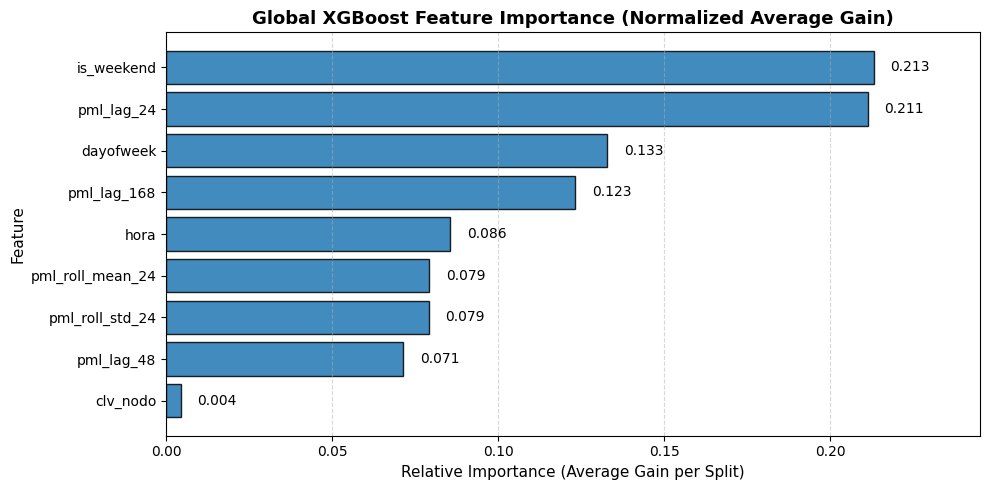

In [4]:
# Extract and plot feature importances (normalized average gain per split)
importance_series = pd.Series(
    xgb_model.feature_importances_,
    index=FEATURE_COLS
).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
bars = plt.barh(importance_series.index, importance_series.values, color="#1f77b4", edgecolor="black", alpha=0.85)
plt.title("Global XGBoost Feature Importance (Normalized Average Gain)", fontsize=13, fontweight="bold")
plt.xlabel("Relative Importance (Average Gain per Split)", fontsize=11)
plt.ylabel("Feature", fontsize=11)
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Value annotations
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", fontsize=10)

plt.xlim(0, max(importance_series.values) * 1.15)
plt.tight_layout()
plt.show()

## 9-Node Validation Performance
We generate day-ahead forecasts across all 19,440 hours of Q1 2025 and evaluate MAE and RMSE across all 9 Monclova nodes.

In [5]:
# Predict validation set with Global XGBoost
val_df["pml_pred_xgb"] = predict_global_xgboost(xgb_model, val_df, feature_cols=FEATURE_COLS).values

all_nodes = sorted(raw_df["clv_nodo"].unique())
node_metrics = []

for node in all_nodes:
    node_val = val_df[val_df["clv_nodo"] == node].sort_values("timestamp").reset_index(drop=True)
    y_true = node_val["pml"].values
    y_xgb = node_val["pml_pred_xgb"].values

    node_metrics.append({
        "Node": node,
        "XGB_MAE": compute_mae(y_true, y_xgb),
        "XGB_RMSE": compute_rmse(y_true, y_xgb),
    })

xgb_perf_df = pd.DataFrame(node_metrics).round(2)

# Overall average row
avg_row = pd.DataFrame([{
    "Node": "OVERALL_AVERAGE",
    "XGB_MAE": xgb_perf_df["XGB_MAE"].mean().round(2),
    "XGB_RMSE": xgb_perf_df["XGB_RMSE"].mean().round(2),
}])

summary_table = pd.concat([xgb_perf_df, avg_row], ignore_index=True)
print("=== Global XGBoost Validation Performance Across All 9 Nodes (Q1 2025) ===")
display(summary_table)

=== Global XGBoost Validation Performance Across All 9 Nodes (Q1 2025) ===


,Node,XGB_MAE,XGB_RMSE
0,06AEO-115,198.27,290.65
1,06AHM-400,196.74,288.55
2,06FRO-115,196.71,288.56
3,06GRA-115,198.10,290.53
4,06MON-115,197.41,289.69
5,06MON-230,197.45,289.76
6,06RGS-115,197.13,288.66
7,06TKS-115,196.91,288.75
8,06XOC-115,198.28,290.60
9,OVERALL_AVERAGE,197.44,289.53


## Forecast Visualizations (Actual PML vs. Global XGBoost)
We inspect the model predictions against actual CENACE MDA prices for the central reference node `06MON-115` across two complementary regimes:
1. **Stress-Test Week (Jan 13–19, 2025):** Unpredicted Sunday spike testing weekend adjustment dynamics.
2. **Typical Regime Week (Feb 3–9, 2025):** Standard, calm winter operating conditions (Mean PML: &#36;580.06/MWh).


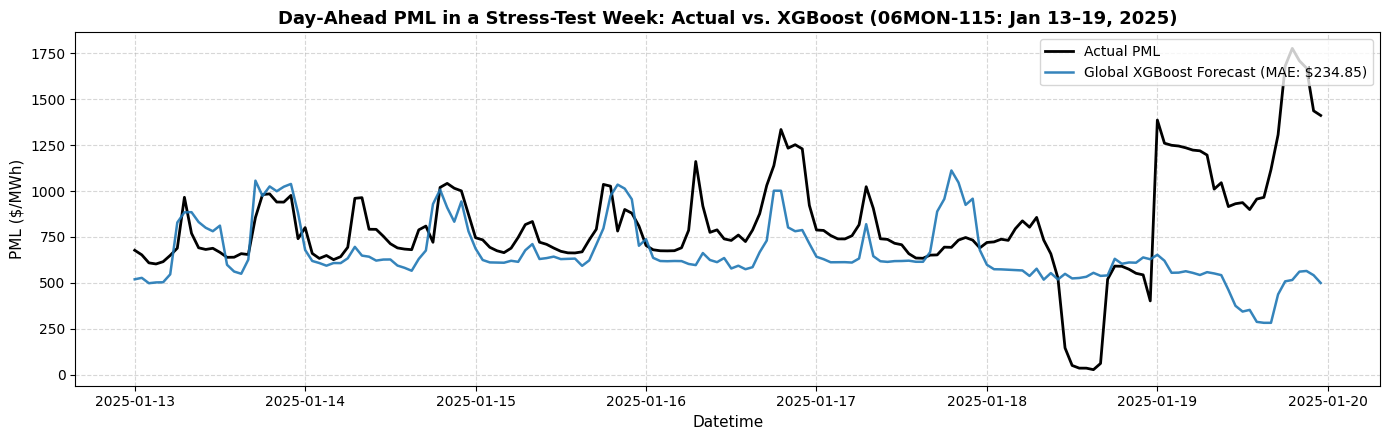

Stress-Test Week Performance (Jan 13–19, 2025): MAE = $234.85 MXN/MWh


In [6]:
REF_NODE = "06MON-115"
ref_val = val_df[val_df["clv_nodo"] == REF_NODE].set_index("timestamp").sort_index()


# Operating Week: Jan 13 - Jan 19, 2025
stress_mask = (ref_val.index >= "2025-01-13") & (ref_val.index <= "2025-01-19 23:00:00")
stress_actual = ref_val.loc[stress_mask, "pml"]
stress_xgb = ref_val.loc[stress_mask, "pml_pred_xgb"]
mae_stress = compute_mae(stress_actual.values, stress_xgb.values)

plt.figure(figsize=(14, 4.5))
plt.plot(stress_actual.index, stress_actual.values, label="Actual PML", color="black", linewidth=2.0)
plt.plot(stress_xgb.index, stress_xgb.values, label=f"Global XGBoost Forecast (MAE: ${mae_stress:.2f})", color="#1f77b4", linestyle="-", linewidth=1.8, alpha=0.9)

plt.title(f"Day-Ahead PML in a Stress-Test Week: Actual vs. XGBoost ({REF_NODE}: Jan 13–19, 2025)", fontsize=13, fontweight="bold")
plt.xlabel("Datetime", fontsize=11)
plt.ylabel("PML ($/MWh)", fontsize=11)
plt.legend(loc="upper right", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Stress-Test Week Performance (Jan 13–19, 2025): MAE = ${mae_stress:.2f} MXN/MWh")

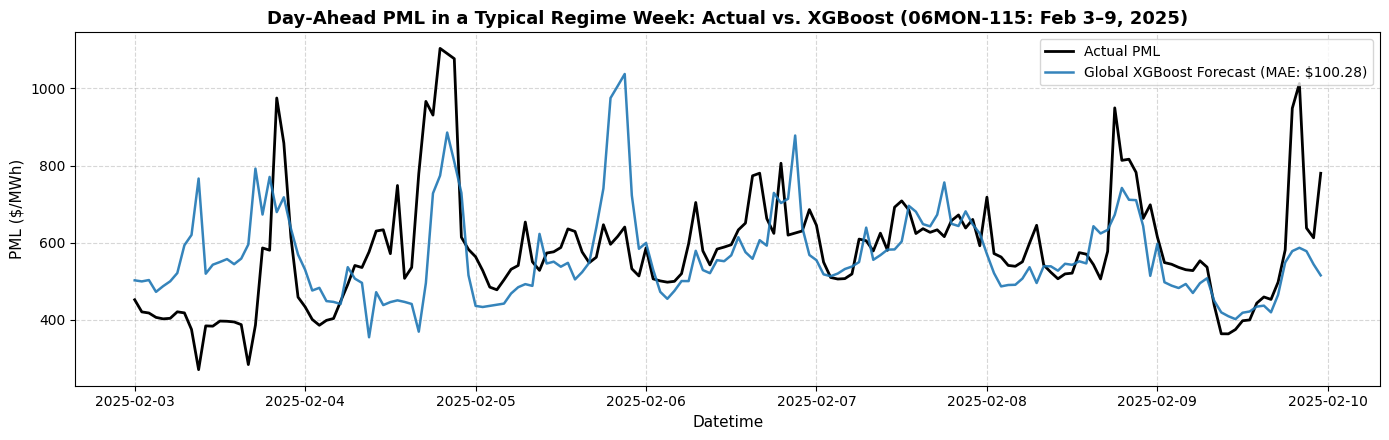

Typical Week Performance (Feb 3–9, 2025): MAE = $100.28 MXN/MWh


In [7]:

# Typical Operating Week: Feb 3 - Feb 9, 2025
normal_mask = (ref_val.index >= "2025-02-03") & (ref_val.index <= "2025-02-09 23:00:00")
norm_actual = ref_val.loc[normal_mask, "pml"]
norm_xgb = ref_val.loc[normal_mask, "pml_pred_xgb"]
mae_typical = compute_mae(norm_actual.values, norm_xgb.values)

plt.figure(figsize=(14, 4.5))
plt.plot(norm_actual.index, norm_actual.values, label="Actual PML", color="black", linewidth=2.0)
plt.plot(norm_xgb.index, norm_xgb.values, label=f"Global XGBoost Forecast (MAE: ${mae_typical:.2f})", color="#1f77b4", linestyle="-", linewidth=1.8, alpha=0.9)

plt.title(f"Day-Ahead PML in a Typical Regime Week: Actual vs. XGBoost ({REF_NODE}: Feb 3–9, 2025)", fontsize=13, fontweight="bold")
plt.xlabel("Datetime", fontsize=11)
plt.ylabel("PML ($/MWh)", fontsize=11)
plt.legend(loc="upper right", frameon=True, fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"Typical Week Performance (Feb 3–9, 2025): MAE = ${mae_typical:.2f} MXN/MWh")

### Modeling Takeaways

1. **Strong Baseline Tracking in Normal Conditions:**
   - In standard winter operating conditions (Feb 3–9, 2025), XGBoost achieves a **MAE of &#36;100.28/MWh**
2. **Robustness in Volatile Regimes:**
   - Under unexpected weekend shocks (Jan 19, 2025), XGBoost adapts based on recent rolling scale (`pml_roll_mean_24`) and avoids negative pricing collapse.
3. **Zone-Wide Consistency:**
   - XGBoost delivers uniform accuracy across all 9 Monclova substations, ranging from &#36;196.71 to &#36;198.28 MAE, with an overall average of **&#36;197.44/MWh MAE** and **&#36;289.53/MWh RMSE**.
4. **Master Benchmark & Test Evaluation:**
   - Comprehensive cross-model benchmarking against Persistence and SARIMAX, along with blind evaluation on the **Test Set (Q2 2025: April 1 – June 30, 2025)** and relative MAE (`rMAE`), is consolidated in `notebooks/05_model_comparison_and_test.ipynb`.